In [4]:
import duckdb
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data_dir = Path("Dataset")

customer_path = data_dir / "customer_data.csv"
transaction_path = data_dir / "transactions_data.csv"

con = duckdb.connect()

print("DuckDB connected successfully!")
print("Customer file:", customer_path.exists())
print("Transaction file:", transaction_path.exists())

DuckDB connected successfully!
Customer file: True
Transaction file: True


In [6]:
customer_schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{customer_path.as_posix()}')
""").df()

display(customer_schema)

,column_name,column_type,null,key,default,extra
0,customer_id,BIGINT,YES,None,None,None
1,age,BIGINT,YES,None,None,None
2,gender,VARCHAR,YES,None,None,None
3,location,VARCHAR,YES,None,None,None
4,income_bracket,VARCHAR,YES,None,None,None
5,occupation,VARCHAR,YES,None,None,None
6,education_level,VARCHAR,YES,None,None,None
7,marital_status,VARCHAR,YES,None,None,None
8,household_size,BIGINT,YES,None,None,None
9,acquisition_channel,VARCHAR,YES,None,None,None


In [7]:
transaction_schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{transaction_path.as_posix()}')
""").df()

display(transaction_schema)

,column_name,column_type,null,key,default,extra
0,customer_id,BIGINT,YES,None,None,None
1,date,DATE,YES,None,None,None
2,amount,BIGINT,YES,None,None,None
3,type,VARCHAR,YES,None,None,None


In [8]:
customer_count = con.execute(f"""
    SELECT COUNT(*)
    FROM read_csv_auto('{customer_path.as_posix()}')
""").fetchone()[0]

transaction_count = con.execute(f"""
    SELECT COUNT(*)
    FROM read_csv_auto('{transaction_path.as_posix()}')
""").fetchone()[0]

print("Total customer:", customer_count)
print("Total transaction:", transaction_count)

Total customer: 48723
Total transaction: 3159157


In [9]:
# MISSING VALUES ANALYSIS

# Customer Data
customer_df = pd.read_csv(customer_path)

missing_customer = pd.DataFrame({
    "missing_values": customer_df.isnull().sum(),
    "missing_percentage": (
        customer_df.isnull().sum() / len(customer_df) * 100
    )
})

missing_customer = missing_customer.sort_values(
    by="missing_percentage", ascending=False
)

display(missing_customer)

,missing_values,missing_percentage
complaint_topics,24346,49.968188
credit_utilization_ratio,18263,37.483324
feature_requests,16115,33.074729
location,0,0.000000
gender,0,0.000000
customer_id,0,0.000000
occupation,0,0.000000
education_level,0,0.000000
household_size,0,0.000000
marital_status,0,0.000000


In [10]:
# MISSING VALUES ANALYSIS

# Transaction Data
transaction_df = pd.read_csv(transaction_path)

missing_transaction = pd.DataFrame({
    "missing_values": transaction_df.isnull().sum(),
    "missing_percentage": (
        transaction_df.isnull().sum() / len(transaction_df) * 100
    )
})

missing_transaction = missing_transaction.sort_values(
    by="missing_percentage", ascending=False
)

display(missing_transaction)

,missing_values,missing_percentage
customer_id,0,0.0
date,0,0.0
amount,0,0.0
type,0,0.0


In [11]:
customer_source = f"read_csv_auto('{customer_path.as_posix()}')"
transaction_source = f"read_csv_auto('{transaction_path.as_posix()}')"

In [12]:
# Duplicate Rows (Customer Data)

result = con.execute(
    f"""
    SELECT 
        COUNT(*) AS total_rows,
        COUNT(DISTINCT customer_id) AS unique_rows,
        COUNT(*) - COUNT(DISTINCT customer_id) AS duplicate_rows
    FROM {customer_source}
""").df()

display(result)

,total_rows,unique_rows,duplicate_rows
0,48723,48723,0


In [13]:
# Duplicate Rows (Transaction Data)

result = con.execute(
    f"""
    WITH t AS (
        SELECT
            *,
            hash(customer_id, date, amount, type) AS row_hash
        FROM {transaction_source}
    )
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(DISTINCT row_hash) AS duplicate_rows
    FROM t
""").df()

display(result)

,total_rows,duplicate_rows
0,3159157,102


In [14]:
result = con.execute(
    f"""
    SELECT
        COUNT(*) FILTER (WHERE age < 0) AS invalid_age,
        COUNT(*) FILTER (WHERE household_size < 0) AS invalid_household_size,
        COUNT(*) FILTER (WHERE active_products < 0) AS invalid_active_products,
        COUNT(*) FILTER (WHERE app_logins_frequency < 0) AS invalid_app_logins,
        COUNT(*) FILTER (WHERE failed_transactions < 0) AS invalid_failed_transactions,
        COUNT(*) FILTER (WHERE tx_count < 0) AS invalid_tx_count,
        COUNT(*) FILTER (WHERE avg_tx_value < 0) AS invalid_avg_tx_value,
        COUNT(*) FILTER (WHERE total_tx_volume < 0) AS invalid_total_tx_volume,
        COUNT(*) FILTER (WHERE churn_probability < 0 OR churn_probability > 1) AS invalid_churn_probability,
        COUNT(*) FILTER (WHERE resolved_tickets_ratio < 0 OR resolved_tickets_ratio > 1) AS invalid_resolved_ratio,
        COUNT(*) FILTER (WHERE weekend_transaction_ratio < 0 OR weekend_transaction_ratio > 1) AS invalid_weekend_ratio,
        COUNT(*) FILTER (WHERE first_tx > last_tx) AS invalid_transaction_dates
    FROM {customer_source}
""").df()

display(result)

,invalid_age,invalid_household_size,invalid_active_products,invalid_app_logins,invalid_failed_transactions,invalid_tx_count,invalid_avg_tx_value,invalid_total_tx_volume,invalid_churn_probability,invalid_resolved_ratio,invalid_weekend_ratio,invalid_transaction_dates
0,0,0,0,0,0,0,0,0,0,0,0,0


In [15]:
# Check for empty IDs, duplicate customer IDs, and transactions without customer data
result = con.execute(
    f"""
    WITH customer_ids AS (
        SELECT DISTINCT customer_id
        FROM {customer_source}
        WHERE customer_id IS NOT NULL
    ),

    customer_duplicates AS (
        SELECT COALESCE(SUM(row_count - 1), 0) AS duplicate_customer_rows
        FROM (
            SELECT 
                customer_id, 
                COUNT(*) AS row_count
            FROM {customer_source}
            WHERE customer_id IS NOT NULL
            GROUP BY customer_id
            HAVING COUNT(*) > 1
        )
    )

    SELECT 
        (
            SELECT COUNT(*)
            FROM {customer_source}
            WHERE customer_id IS NULL
        ) AS customer_missing_id,

        (
            SELECT duplicate_customer_rows
            FROM customer_duplicates
        ) AS duplicate_customer_id_rows,

        (
            SELECT COUNT(*)
            FROM {transaction_source}
            WHERE customer_id IS NULL
        ) AS transactions_with_missing_id,

        (
            SELECT COUNT(*)
            FROM {transaction_source} AS t
            LEFT JOIN customer_ids AS c
                ON t.customer_id = c.customer_id
            WHERE t.customer_id IS NOT NULL
                AND c.customer_id IS NULL
        ) AS transactions_without_customer_record
    """
).df()

display(result)

,customer_missing_id,duplicate_customer_id_rows,transactions_with_missing_id,transactions_without_customer_record
0,0,0.0,0,0


In [16]:
# Check the date range and transactions per month
result = con.execute(
    f"""
    SELECT
        MIN(date) AS first_transaction_date,
        MAX(date) AS last_transaction_date,
        COUNT(*) FILTER (WHERE date IS NULL) AS missing_transaction_dates,
        COUNT(DISTINCT date) AS distinct_transaction_dates
    FROM {transaction_source}
    """
).df()

display(result)


monthly_transactions = con.execute(
    f"""
    SELECT
        DATE_TRUNC('month', date)::DATE AS month,
        COUNT(*) AS transaction_count,
        SUM(amount) AS total_amount
    FROM {transaction_source}
    WHERE date IS NOT NULL
    GROUP BY month
    ORDER BY month
    """
).df()

monthly_transactions["month"] = pd.to_datetime(monthly_transactions["month"])

if not monthly_transactions.empty:
    all_months = pd.DataFrame({
        "month": pd.date_range(
            start=monthly_transactions["month"].min(),
            end=monthly_transactions["month"].max(),
            freq="MS",
        )
    })

    monthly_transactions = all_months.merge(
        monthly_transactions,
        on="month",
        how="left",
    )

    monthly_transactions[["transaction_count", "total_amount"]] = (
        monthly_transactions[["transaction_count", "total_amount"]]
        .fillna(0)
    )

display(monthly_transactions)

,first_transaction_date,last_transaction_date,missing_transaction_dates,distinct_transaction_dates
0,2023-01-04,2023-12-29,0,360


,month,transaction_count,total_amount
0,2023-01-01,245641,9.318868e+11
1,2023-02-01,244687,9.080754e+11
2,2023-03-01,271531,1.037939e+12
3,2023-04-01,262739,9.904653e+11
4,2023-05-01,271948,1.020757e+12
5,2023-06-01,263295,1.305738e+12
6,2023-07-01,272652,1.020921e+12
7,2023-08-01,271937,1.327192e+12
8,2023-09-01,263439,1.007279e+12
9,2023-10-01,272973,1.022768e+12


In [17]:
# Check the category value that appears most frequently
result = con.execute(
    f"""
    SELECT 
        'gender' AS column_name, 
        CAST(gender AS VARCHAR) AS category, 
        COUNT(*) AS row_count
    FROM {customer_source}
    GROUP BY gender

    UNION ALL

    SELECT 
        'location' AS column_name,
        CAST(location AS VARCHAR) AS category,
        COUNT(*) AS row_count
    FROM {customer_source}
    GROUP BY location

    UNION ALL

    SELECT 
        'income_bracket' AS column_name,
        CAST(income_bracket AS VARCHAR) AS category,
        COUNT(*) AS row_count
    FROM {customer_source}
    GROUP BY income_bracket

    UNION ALL

    SELECT 
        'customer_segment' AS column_name,
        CAST(customer_segment AS VARCHAR) AS category,
        COUNT(*) AS row_count
    FROM {customer_source}
    GROUP BY customer_segment

    UNION ALL

    SELECT 
        'transaction_type' AS column_name,
        CAST(type AS VARCHAR) AS category,
        COUNT(*) AS row_count
    FROM {transaction_source}
    GROUP BY type

    ORDER BY column_name, row_count DESC
    """
).df()

display(result)

,column_name,category,row_count
0,customer_segment,occasional,19391
1,customer_segment,regular,14568
2,customer_segment,inactive,9904
3,customer_segment,power,4860
4,gender,Female,24033
5,gender,Male,23761
6,gender,Other,929
7,income_bracket,Medium,19489
8,income_bracket,Low,14617
9,income_bracket,High,12180


In [18]:
# Check the distribution of numerical values ​​and extreme values
transaction_amount_summary = con.execute(
    f"""
    SELECT
        MIN(amount) AS min_amount,
        QUANTILE_CONT(amount, 0.25) AS q1_amount,
        QUANTILE_CONT(amount, 0.50) AS median_amount,
        QUANTILE_CONT(amount, 0.75) AS q3_amount,
        QUANTILE_CONT(amount, 0.95) AS p95_amount,
        QUANTILE_CONT(amount, 0.99) AS p99_amount,
        MAX(amount) AS max_amount,
        COUNT(*) FILTER (WHERE amount < 0) AS negative_amount_rows,
        COUNT(*) FILTER (WHERE amount = 0) AS zero_amount_rows
    FROM {transaction_source}
    """
).df()

customer_numeric_summary = con.execute(
    f"""
    SELECT
        'age' AS column_name,
        MIN(age) AS min_value,
        QUANTILE_CONT(age, 0.50) AS median_value,
        QUANTILE_CONT(age, 0.95) AS p95_value,
        MAX(age) AS max_value
    FROM {customer_source}

    UNION ALL

    SELECT
        'tx_count' AS column_name,
        MIN(tx_count),
        QUANTILE_CONT(tx_count, 0.50),
        QUANTILE_CONT(tx_count, 0.95),
        MAX(tx_count)
    FROM {customer_source}

    UNION ALL

    SELECT
        'avg_tx_value',
        MIN(avg_tx_value),
        QUANTILE_CONT(avg_tx_value, 0.50),
        QUANTILE_CONT(avg_tx_value, 0.95),
        MAX(avg_tx_value)
    FROM {customer_source}

    UNION ALL

    SELECT
        'customer_lifetime_value',
        MIN(customer_lifetime_value),
        QUANTILE_CONT(customer_lifetime_value, 0.50),
        QUANTILE_CONT(customer_lifetime_value, 0.95),
        MAX(customer_lifetime_value)
    FROM {customer_source}
    """
).df()

display(transaction_amount_summary)
display(customer_numeric_summary)

,min_amount,q1_amount,median_amount,q3_amount,p95_amount,p99_amount,max_amount,negative_amount_rows,zero_amount_rows
0,36400,828550.0,1788300.0,4184700.0,14697270.0,33028806.0,689739900,0,0


,column_name,min_value,median_value,p95_value,max_value
0,age,29.0,4.500000e+01,6.000000e+01,6.000000e+01
1,tx_count,10.0,1.800000e+01,1.509000e+02,7.746500e+04
2,avg_tx_value,318215.0,1.763107e+06,1.360161e+07,5.167030e+07
3,customer_lifetime_value,0.0,1.296820e+08,1.154373e+09,1.776860e+10


In [19]:
# Compare customer metrics with aggregated transaction results
metric_consistency = con.execute(
    f"""
    WITH transaction_summary AS (
        SELECT
            customer_id,
            COUNT(*) AS calculated_tx_count,
            AVG(amount) AS calculated_avg_tx_value,
            SUM(amount) AS calculated_total_tx_volume,
            MIN(date) AS calculated_first_tx,
            MAX(date) AS calculated_last_tx
        FROM {transaction_source}
        WHERE customer_id IS NOT NULL
        GROUP BY customer_id
    )
    SELECT
        COUNT(*) FILTER (
            WHERE t.customer_id IS NULL
        ) AS customers_without_transactions,

        COUNT(*) FILTER (
            WHERE t.customer_id IS NOT NULL
                AND c.tx_count IS DISTINCT FROM t.calculated_tx_count
        ) AS tx_count_mismatches,

        COUNT(*) FILTER (
            WHERE t.customer_id IS NOT NULL
                AND (
                    c.avg_tx_value IS NULL
                    OR ABS(c.avg_tx_value - t.calculated_avg_tx_value) > 0.01
                )
        ) AS avg_tx_value_mismatches,

        COUNT(*) FILTER (
            WHERE t.customer_id IS NOT NULL
                AND c.total_tx_volume IS DISTINCT FROM t.calculated_total_tx_volume
        ) AS total_tx_volume_mismatches,

        COUNT(*) FILTER (
            WHERE t.customer_id IS NOT NULL
                AND c.first_tx IS DISTINCT FROM t.calculated_first_tx
        ) AS first_tx_mismatches,

        COUNT(*) FILTER (
            WHERE t.customer_id IS NOT NULL
                AND c.last_tx IS DISTINCT FROM t.calculated_last_tx
        ) AS last_tx_mismatches

    FROM {customer_source} AS c
    LEFT JOIN transaction_summary AS t
        ON c.customer_id = t.customer_id
    """
).df()

display(metric_consistency)

,customers_without_transactions,tx_count_mismatches,avg_tx_value_mismatches,total_tx_volume_mismatches,first_tx_mismatches,last_tx_mismatches
0,0,0,0,0,0,0


In [20]:
# Check the distribution of age values
age_distribution = con.execute(
    f"""
    SELECT
        age,
        COUNT(*) AS customer_count,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM {customer_source}
    GROUP BY age
    ORDER BY age DESC
    """
).df()

display(age_distribution)

,age,customer_count,percentage
0,60,8175,16.78
1,59,8190,16.81
2,45,8082,16.59
3,44,8057,16.54
4,30,8104,16.63
5,29,8115,16.66


In [21]:
# Identify 20 custommers with the highest 'tx_count'
outlier_check = con.execute(
    f"""
    WITH thresholds AS (
        SELECT
            QUANTILE_CONT(tx_count, 0.95) AS p95_tx_count,
            QUANTILE_CONT(customer_lifetime_value, 0.95) AS p95_clv
        FROM {customer_source}
    ),
    top_customers AS (
        SELECT
            c.customer_id,
            c.age,
            c.tx_count,
            c.avg_tx_value,
            c.total_tx_volume,
            c.customer_lifetime_value,
            t.p95_tx_count,
            t.p95_clv
        FROM {customer_source} AS c
        CROSS JOIN thresholds AS t
        WHERE c.tx_count > t.p95_tx_count
            OR c.customer_lifetime_value > t.p95_clv
        ORDER BY c.tx_count DESC, c.customer_lifetime_value DESC
        LIMIT 20
    )
    SELECT
        c.customer_id,
        c.age,
        c.tx_count AS customer_tx_count,
        COUNT(t.customer_id) AS transaction_rows,
        c.avg_tx_value AS customer_avg_tx_value,
        AVG(t.amount) AS calculated_avg_tx_value,
        c.total_tx_volume AS customer_total_volume,
        SUM(t.amount) AS calculated_total_volume,
        MIN(t.date) AS first_transaction_date,
        MAX(t.date) AS last_transaction_date,
        c.customer_lifetime_value,
        c.p95_tx_count,
        c.p95_clv
    FROM top_customers AS c
    LEFT JOIN {transaction_source} AS t
        ON c.customer_id = t.customer_id
    GROUP BY
        c.customer_id,
        c.age,
        c.tx_count,
        c.avg_tx_value,
        c.total_tx_volume,
        c.customer_lifetime_value,
        c.p95_tx_count,
        c.p95_clv
    ORDER BY customer_tx_count DESC, c.customer_lifetime_value DESC
    """
).df()

display(outlier_check)

,customer_id,age,customer_tx_count,transaction_rows,customer_avg_tx_value,calculated_avg_tx_value,customer_total_volume,calculated_total_volume,first_transaction_date,last_transaction_date,customer_lifetime_value,p95_tx_count,p95_clv
0,87831169,45,77465,77465,1.385254e+07,1.385254e+07,1073087373150,1.073087e+12,2023-01-04,2023-12-29,0.000000e+00,150.9,1.154373e+09
1,41089287,60,36792,36792,1.389622e+07,1.389622e+07,511269898750,5.112699e+11,2023-01-04,2023-12-29,4.802437e+01,150.9,1.154373e+09
2,10435643,59,35499,35499,5.685891e+05,5.685891e+05,20184344600,2.018434e+10,2023-01-04,2023-12-29,8.682129e+00,150.9,1.154373e+09
3,79060117,45,27472,27472,1.374423e+07,1.374423e+07,377581503150,3.775815e+11,2023-01-04,2023-12-29,1.577993e+04,150.9,1.154373e+09
4,20318435,44,27191,27191,1.401466e+07,1.401466e+07,381072706550,3.810727e+11,2023-01-04,2023-12-29,1.880819e+04,150.9,1.154373e+09
5,89007515,45,23972,23972,1.631617e+06,1.631617e+06,39113116600,3.911312e+10,2023-01-04,2023-12-29,2.964632e+04,150.9,1.154373e+09
6,76469096,60,23073,23073,1.621879e+06,1.621879e+06,37421625650,3.742163e+10,2023-01-04,2023-12-29,5.149577e+04,150.9,1.154373e+09
7,18934638,59,22680,22680,1.617430e+06,1.617430e+06,36683310800,3.668331e+10,2023-01-04,2023-12-29,6.490774e+04,150.9,1.154373e+09
8,87515629,29,21437,21437,1.387779e+07,1.387779e+07,297498281300,2.974983e+11,2023-01-04,2023-12-29,6.466147e+05,150.9,1.154373e+09
9,41099208,60,20816,20816,4.749414e+06,4.749414e+06,98863794550,9.886379e+10,2023-01-04,2023-12-29,5.000959e+05,150.9,1.154373e+09


In [22]:
# Check whether null values ​​are related to other columns
missing_context = con.execute(
    f"""
    SELECT
        CASE
            WHEN complaint_topics IS NULL THEN 'complaint_topics kosong'
            ELSE 'complaint_topics terisi'
        END AS complaint_status,
        CASE
            WHEN support_tickets_count = 0 THEN 'tanpa tiket'
            WHEN support_tickets_count > 0 THEN 'ada tiket'
            ELSE 'jumlah tiket kosong'
        END AS ticket_status,
        COUNT(*) AS customer_count
    FROM {customer_source}
    GROUP BY complaint_status, ticket_status
    ORDER BY complaint_status, ticket_status
    """
).df()

credit_utilization_context = con.execute(
    f"""
    SELECT
        credit_card,
        CASE
            WHEN credit_utilization_ratio IS NULL THEN 'rasio kosong'
            ELSE 'rasio terisi'
        END AS ratio_status,
        COUNT(*) AS customer_count
    FROM {customer_source}
    GROUP BY credit_card, ratio_status
    ORDER BY credit_card, ratio_status
    """
).df()

display(missing_context)
display(credit_utilization_context)

,complaint_status,ticket_status,customer_count
0,complaint_topics kosong,ada tiket,15386
1,complaint_topics kosong,tanpa tiket,8960
2,complaint_topics terisi,ada tiket,15423
3,complaint_topics terisi,tanpa tiket,8954


,credit_card,ratio_status,customer_count
0,False,rasio kosong,18263
1,True,rasio terisi,30460


In [23]:
sns.set_theme(style="whitegrid", palette="deep")

# Load data
customers = pd.read_csv("Dataset/customer_data.csv")
transactions = pd.read_csv("Dataset/transactions_data.csv")

transactions["date"] = pd.to_datetime(transactions["date"], errors="coerce")
transactions["amount"] = pd.to_numeric(transactions["amount"], errors="coerce")

# Cek ukuran dan data yang hilang
print("Jumlah customer:", customers.shape[0])
print("Jumlah transaksi:", transactions.shape[0])
print("\nKolom customer dengan nilai kosong terbanyak:")
print(customers.isna().sum().sort_values(ascending=False).head(10))

Jumlah customer: 48723
Jumlah transaksi: 3159157

Kolom customer dengan nilai kosong terbanyak:
complaint_topics            24346
credit_utilization_ratio    18263
feature_requests            16115
location                        0
gender                          0
customer_id                     0
occupation                      0
education_level                 0
household_size                  0
marital_status                  0
dtype: int64


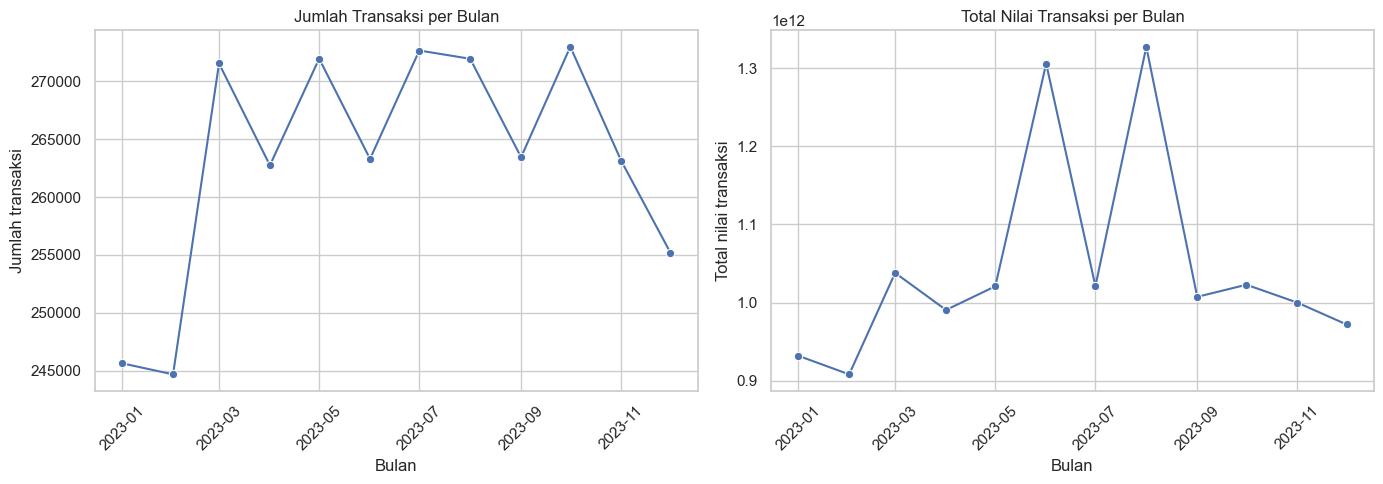

In [25]:
monthly = (
    transactions.dropna(subset=["date"])
    .assign(month=lambda df: df["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(
        transaction_count=("customer_id", "size"),
        total_amount=("amount", "sum"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=monthly, x="month", y="transaction_count",
    marker="o", ax=axes[0]
)
axes[0].set_title("Jumlah Transaksi per Bulan")
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Jumlah transaksi")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=monthly, x="month", y="total_amount",
    marker="o", ax=axes[1]
)
axes[1].set_title("Total Nilai Transaksi per Bulan")
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Total nilai transaksi")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

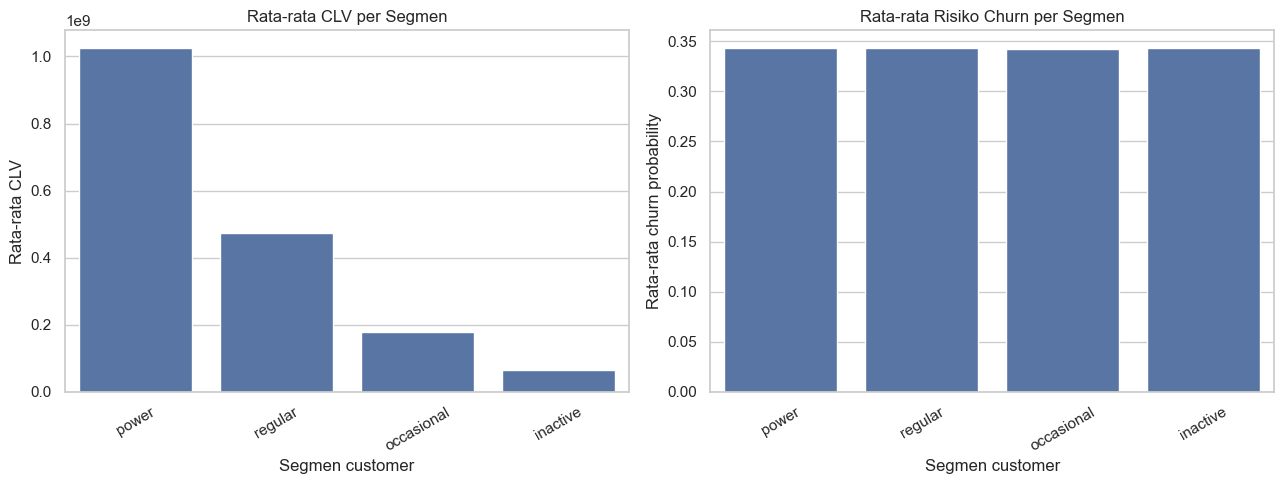

In [26]:
segment_metrics = (
    customers.groupby("customer_segment", dropna=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        avg_clv=("customer_lifetime_value", "mean"),
        avg_churn=("churn_probability", "mean"),
    )
    .reset_index()
    .sort_values("avg_clv", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=segment_metrics, x="customer_segment", y="avg_clv", ax=axes[0]
)
axes[0].set_title("Rata-rata CLV per Segmen")
axes[0].set_xlabel("Segmen customer")
axes[0].set_ylabel("Rata-rata CLV")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=segment_metrics, x="customer_segment", y="avg_churn", ax=axes[1]
)
axes[1].set_title("Rata-rata Risiko Churn per Segmen")
axes[1].set_xlabel("Segmen customer")
axes[1].set_ylabel("Rata-rata churn probability")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

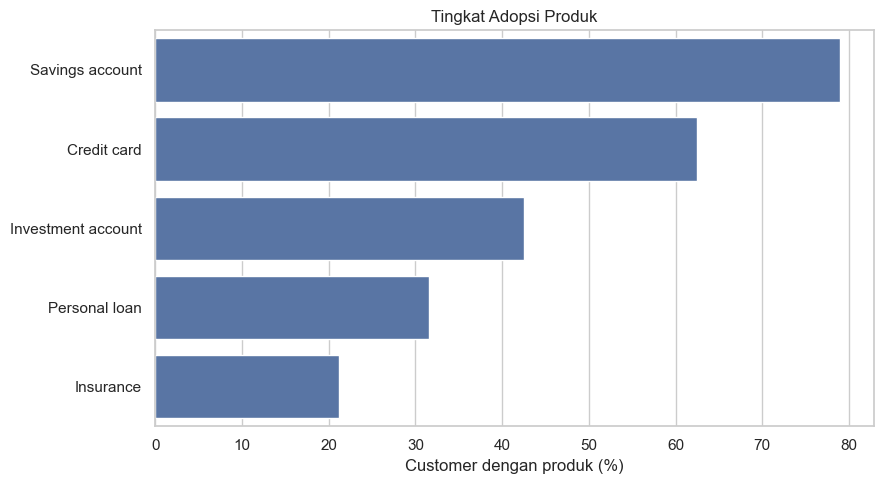

In [27]:
product_columns = {
    "Savings account": "savings_account",
    "Credit card": "credit_card",
    "Personal loan": "personal_loan",
    "Investment account": "investment_account",
    "Insurance": "insurance_product",
}

adoption = pd.DataFrame([
    {
        "product": label,
        "adoption_rate_pct": customers[column].eq(True).mean() * 100,
    }
    for label, column in product_columns.items()
]).sort_values("adoption_rate_pct", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=adoption, x="adoption_rate_pct", y="product")
plt.title("Tingkat Adopsi Produk")
plt.xlabel("Customer dengan produk (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

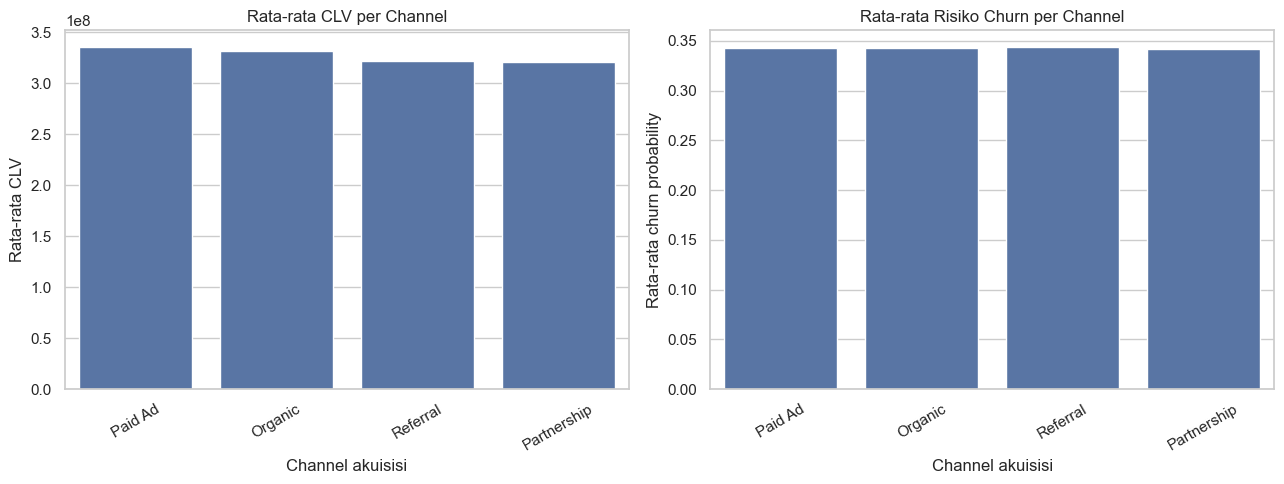

In [28]:
channel_metrics = (
    customers.groupby("acquisition_channel", dropna=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        avg_clv=("customer_lifetime_value", "mean"),
        avg_churn=("churn_probability", "mean"),
    )
    .reset_index()
    .sort_values("avg_clv", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=channel_metrics, x="acquisition_channel", y="avg_clv", ax=axes[0]
)
axes[0].set_title("Rata-rata CLV per Channel")
axes[0].set_xlabel("Channel akuisisi")
axes[0].set_ylabel("Rata-rata CLV")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=channel_metrics, x="acquisition_channel", y="avg_churn", ax=axes[1]
)
axes[1].set_title("Rata-rata Risiko Churn per Channel")
axes[1].set_xlabel("Channel akuisisi")
axes[1].set_ylabel("Rata-rata churn probability")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()